# BMI 500 — HW3 Part A | Blood Pressure Model Fitting

I used approximate blood pressure data from Figure 3 of Mousavi et al. to compare polynomial, sigmoid, and Gaussian models for males and females using MSE, R², and BIC.

## 0. Embedded Figure 3 CSV — editable source data
I included the estimated data from Figure 3 directly in this notebook, so no separate CSV file is needed. The data can be updated in the code below.

In [16]:
from io import StringIO
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from IPython.display import display

csv_text = r'''age_group,age_midpoint_years_assumed,sex,mean_sbp_mmHg_APPROX,mean_dbp_mmHg_APPROX,source,extraction_status
<10,5,Female,103,61,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
<10,5,Male,104,69,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
10-20,15,Female,111,69,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
10-20,15,Male,120,75,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
20-30,25,Female,118,72,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
20-30,25,Male,125,79,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
30-40,35,Female,121,75,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
30-40,35,Male,128,81,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
40-50,45,Female,125,77,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
40-50,45,Male,130,82,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
50-60,55,Female,129,79,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
50-60,55,Male,132,81,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
60-70,65,Female,133,77,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
60-70,65,Male,133,79,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
70-80,75,Female,136,75,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
70-80,75,Male,134,76,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
80-90,85,Female,139,72,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
80-90,85,Male,134,73,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
>90,95,Female,140,69,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE
>90,95,Male,134,70,Figure 3 (arXiv PDF page 4),VISUAL_ESTIMATE_NOT_AUTHOR_TABLE'''
df = pd.read_csv(StringIO(csv_text))
required = {'age_midpoint_years_assumed', 'sex', 'mean_sbp_mmHg_APPROX', 'mean_dbp_mmHg_APPROX'}
assert required.issubset(df.columns), f'Missing CSV fields: {required - set(df.columns)}'
assert set(df['sex']) == {'Male', 'Female'}
assert df.groupby('sex').size().eq(10).all()

SAVE_RESULTS = False  
print(f"Embedded data loaded: {len(df)} graph-estimated rows, {df.sex.nunique()} sexes")
display(df[['age_group', 'age_midpoint_years_assumed', 'sex',
            'mean_sbp_mmHg_APPROX', 'mean_dbp_mmHg_APPROX']])


Embedded data loaded: 20 graph-estimated rows, 2 sexes


,age_group,age_midpoint_years_assumed,sex,mean_sbp_mmHg_APPROX,mean_dbp_mmHg_APPROX
0,<10,5,Female,103,61
1,<10,5,Male,104,69
2,10-20,15,Female,111,69
3,10-20,15,Male,120,75
4,20-30,25,Female,118,72
5,20-30,25,Male,125,79
6,30-40,35,Female,121,75
7,30-40,35,Male,128,81
8,40-50,45,Female,125,77
9,40-50,45,Male,130,82


## 1. Candidate models and fitting strategy

For age $a$ (years):

 $y(a)=c_1a^2+c_2a+c_3$; coefficients found using **linear least squares**.

 $\mathrm{SBP}(a)=S_0+\frac{\Delta S}{1+\exp[-k(a-a_0)]}$.

 $\mathrm{DBP}(a)=D_0+\Delta D\exp[-(a-a_{\mathrm{peak}})^2/(2\sigma^2)]$.

I used nonlinear least squares to fit the sigmoid and Gaussian models.

In [17]:
def quadratic(a, c1, c2, c3):
    a = np.asarray(a, dtype=float)
    return c1*a*a + c2*a + c3

def sigmoid_sbp(a, S0, delta_S, k, a0):
    a = np.asarray(a, dtype=float)
    return S0 + delta_S / (1.0 + np.exp(-np.clip(k*(a-a0), -700, 700)))

def gaussian_dbp(a, D0, delta_D, a_peak, sigma):
    a = np.asarray(a, dtype=float)
    return D0 + delta_D * np.exp(-0.5*((a-a_peak)/sigma)**2)

def fit_quadratic(x,y):
    coeffs = np.linalg.lstsq(np.column_stack([x*x, x, np.ones_like(x)]), y, rcond=None)[0]
    return coeffs

def fit_nonlinear(kind,x,y):
    if kind == 'SBP':
        model = sigmoid_sbp
        p0 = [float(y.min()-3), float(y.max()-y.min()+6), 0.055, 40.0]
        lower, upper = [40,0,0.001,-50],[180,150,0.9,140]
    else:
        model = gaussian_dbp
        p0 = [float(y.min()-3), float(y.max()-y.min()+4), float(x[np.argmax(y)]), 30.0]
        lower, upper = [35,0,0,1],[130,100,110,120]
    popt, _ = curve_fit(model,x,y,p0=p0,bounds=(lower,upper),maxfev=50000)
    return popt

def scores(y, yhat, n_parameters):
    n = len(y)
    sse = float(np.sum((y-yhat)**2))
    mse = sse / n
    sst = float(np.sum((y-y.mean())**2))
    r2 = 1 - sse/sst if sst>0 else np.nan
    bic = n*np.log(max(sse/n, np.finfo(float).tiny)) + n_parameters*np.log(n)
    return {'MSE':mse,'R2':r2,'BIC':bic,'SSE':sse}

## 2. Model Fitting and Results

I fitted eight models and compared their performance using MSE, R², and BIC.

In [18]:
metrics = []
parameters = []
fitted = {}
for sex in ['Female','Male']:
    subset = df[df.sex==sex].sort_values('age_midpoint_years_assumed')
    x = subset['age_midpoint_years_assumed'].to_numpy(dtype=float)
    for outcome, column in [('SBP','mean_sbp_mmHg_APPROX'),('DBP','mean_dbp_mmHg_APPROX')]:
        y = subset[column].to_numpy(dtype=float)
        models = {
            'Polynomial': (quadratic, fit_quadratic(x,y), ['c1','c2','c3']),
            ('Sigmoid' if outcome=='SBP' else 'Gaussian'): (
                sigmoid_sbp if outcome=='SBP' else gaussian_dbp,
                fit_nonlinear(outcome,x,y),
                ['S0','delta_S','k','a0'] if outcome=='SBP' else ['D0','delta_D','a_peak','sigma']
            )
        }
        for model_name,(func,popt,names) in models.items():
            predicted = func(x,*popt)
            record = {'sex':sex, 'outcome':outcome, 'model':model_name, 'n_age_bins':len(y),
                      'n_parameters':len(popt), **scores(y,predicted,len(popt))}
            metrics.append(record)
            parameters += [{'sex':sex,'outcome':outcome,'model':model_name,'parameter':key,'value':float(val)}
                           for key,val in zip(names,popt)]
            fitted[(sex,outcome,model_name)] = (func,popt,x,y)
metrics_df = pd.DataFrame(metrics)
params_df = pd.DataFrame(parameters)
if SAVE_RESULTS:
    Path('outputs').mkdir(exist_ok=True)
    metrics_df.to_csv('outputs/partA_fit_metrics.csv', index=False)
    params_df.to_csv('outputs/partA_fit_parameters.csv', index=False)
print('Model comparison (graph-estimated data; in-sample metrics):')
display(metrics_df[['sex','outcome','model','n_age_bins','n_parameters','MSE','R2','BIC']].round(4))
print('Estimated model coefficients:')
display(params_df.round(5))

Model comparison (graph-estimated data; in-sample metrics):


,sex,outcome,model,n_age_bins,n_parameters,MSE,R2,BIC
0,Female,SBP,Polynomial,10,3,0.7012,0.9949,3.3583
1,Female,SBP,Sigmoid,10,4,0.7440,0.9945,6.2535
2,Female,DBP,Polynomial,10,3,0.5374,0.9787,0.6981
3,Female,DBP,Gaussian,10,4,0.7631,0.9698,6.5061
4,Male,SBP,Polynomial,10,3,5.8430,0.9268,24.5603
5,Male,SBP,Sigmoid,10,4,1.3005,0.9837,11.8374
6,Male,DBP,Polynomial,10,3,0.7556,0.9615,4.1054
7,Male,DBP,Gaussian,10,4,0.6100,0.9690,4.2670


Estimated model coefficients:


,sex,outcome,model,parameter,value
0,Female,SBP,Polynomial,c1,-0.00280
1,Female,SBP,Polynomial,c2,0.67970
2,Female,SBP,Polynomial,c3,100.83523
3,Female,SBP,Sigmoid,S0,40.00000
4,Female,SBP,Sigmoid,delta_S,107.42697
5,Female,SBP,Sigmoid,k,0.02471
6,Female,SBP,Sigmoid,a0,-10.92432
7,Female,DBP,Polynomial,c1,-0.00625
8,Female,DBP,Polynomial,c2,0.69530
9,Female,DBP,Polynomial,c3,58.61610


## 3. Model Fitting Plots

I plotted the blood pressure data and fitted curves for males and females to compare the models.

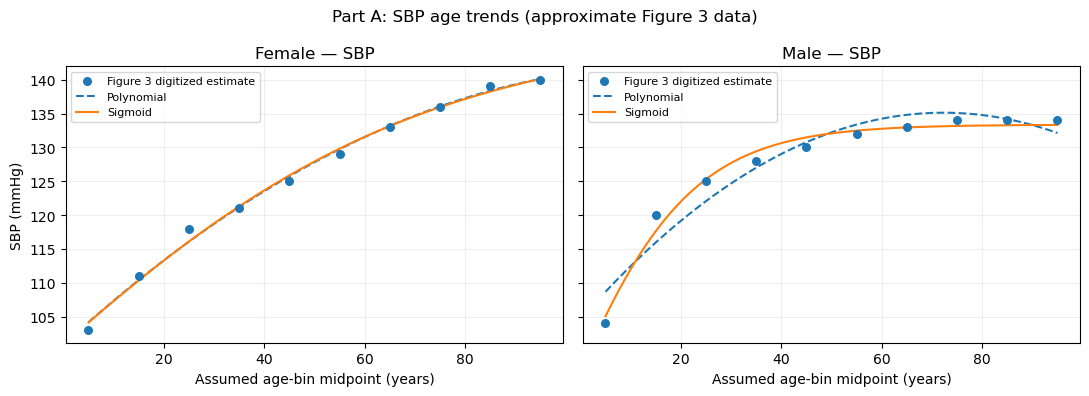

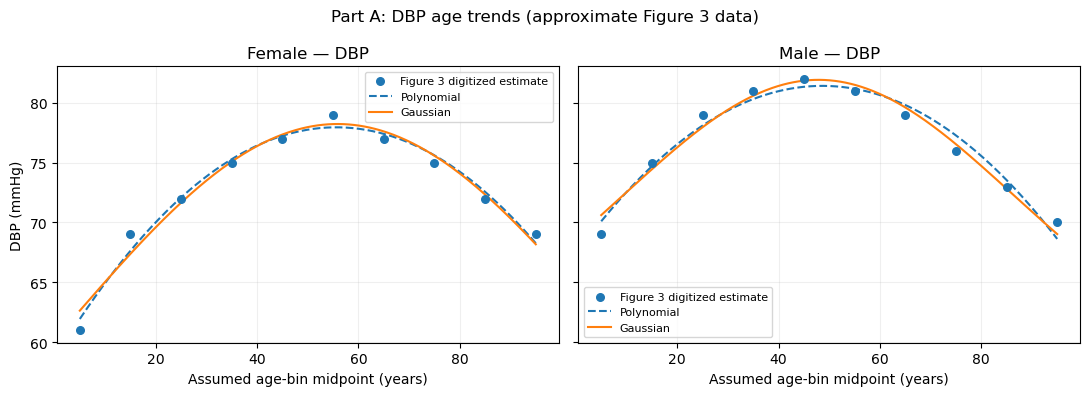

In [19]:
for outcome in ['SBP','DBP']:
    figure, axes = plt.subplots(1,2,figsize=(11,4),sharey=True)
    for ax, sex in zip(axes,['Female','Male']):
        model2='Sigmoid' if outcome=='SBP' else 'Gaussian'
        _,_,x,y=fitted[(sex,outcome,'Polynomial')]
        grid=np.linspace(x.min(),x.max(),350)
        ax.scatter(x,y,label='Figure 3 digitized estimate',s=30,zorder=3)
        for model_name,style in [('Polynomial','--'),(model2,'-')]:
            func,popt,_,_=fitted[(sex,outcome,model_name)]
            ax.plot(grid,func(grid,*popt),ls=style,label=model_name)
        ax.set_title(f'{sex} — {outcome}')
        ax.set_xlabel('Assumed age-bin midpoint (years)')
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    axes[0].set_ylabel(f'{outcome} (mmHg)')
    figure.suptitle(f'Part A: {outcome} age trends (approximate Figure 3 data)')
    figure.tight_layout()
    if SAVE_RESULTS:
        Path('figures').mkdir(exist_ok=True)
        figure.savefig(f'figures/partA_{outcome}_models.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(figure)

## 4. Model Comparison Using BIC

I used BIC to compare the models because it considers both fitting error and model complexity.

In [20]:
comparison=[]
for (sex,outcome), group in metrics_df.groupby(['sex','outcome'],sort=False):
    winner=group.loc[group.BIC.idxmin()]
    comparison.append({'sex':sex,'outcome':outcome,'lower_BIC_model':winner.model,
                       'BIC_difference_to_other':round(float(group.BIC.max()-group.BIC.min()),3)})
comparison_df=pd.DataFrame(comparison)
display(comparison_df)

,sex,outcome,lower_BIC_model,BIC_difference_to_other
0,Female,SBP,Polynomial,2.895
1,Female,DBP,Polynomial,5.808
2,Male,SBP,Sigmoid,12.723
3,Male,DBP,Polynomial,0.162


## 5. Parameter Interpretation and Limitations

For the quadratic model, c1 controls curvature (mmHg/year²), c2 describes the age trend (mmHg/year), and c3 is the intercept (mmHg).

For the sigmoid model, S0 is the baseline, ΔS is the increase (both in mmHg), a0 is the midpoint age (years), and k controls how quickly blood pressure rises (year⁻¹).

For the Gaussian model, D0 is the baseline, ΔD is the peak increase (both in mmHg), apeak is the peak age, and σ controls the peak width (both in years).

Since the data were estimated from a figure, the fitted parameters may not be accurate, especially outside the observed age range.